# 01 · Twenty projections, drawn and measured

This notebook makes every map for the projections story and measures how much each projection distorts the world.

**What it produces**
- `figures/NN-slug.png`: one map per projection, with Tissot's indicatrix (identical circles on the globe, drawn as the projection stretches them)
- `figures/00-contact-sheet.png`: all 20 on one image
- `data/scorecard.csv`: three distortion numbers per projection

**How to run it:** `conda activate geo`, then `jupyter lab` from the `map-projections` folder, and run the cells top to bottom. The first run downloads Natural Earth data through cartopy, so it needs internet.

Each cell prints what it made. Judgement calls are marked **Choice:** so you can argue with them.

In [13]:
from pathlib import Path
import numpy as np
import pandas as pd
import geopandas as gpd
import shapely
import shapely.geometry as sgeom
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.path as mpath
import cartopy
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cartopy.io.shapereader as shpreader
import pyproj
import warnings

# Two harmless warnings fire on almost every map: shapely complaining about NaN
# coordinates at map edges, and cartopy noting it treats lon/lat as PlateCarree.
warnings.filterwarnings("ignore", message="invalid value encountered", category=RuntimeWarning)
warnings.filterwarnings("ignore", message="Approximating coordinate system", category=UserWarning)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG, DATA = ROOT / "figures", ROOT / "data"
FIG.mkdir(exist_ok=True); DATA.mkdir(exist_ok=True)

print("project folder:", ROOT)
print("cartopy", cartopy.__version__, "| pyproj", pyproj.__version__, "| PROJ", pyproj.proj_version_str,
      "| geopandas", gpd.__version__, "| matplotlib", matplotlib.__version__)

project folder: /Users/devi/map-projections
cartopy 0.25.0 | pyproj 3.7.1 | PROJ 9.5.1 | geopandas 1.1.1 | matplotlib 3.10.8


## 1 · Data

Natural Earth, via cartopy's downloader:
- **land, 50m**: for drawing the maps
- **land, 110m**: for the distortion measurements (coarser is fine for that, and faster)
- **countries, 50m**: just to pick out Greenland and Africa

The true areas are measured on the WGS84 ellipsoid with `pyproj.Geod`, so they don't depend on any projection.

In [14]:
land110 = gpd.read_file(shpreader.natural_earth(resolution="110m", category="physical", name="land"))
countries = gpd.read_file(shpreader.natural_earth(resolution="50m", category="cultural", name="admin_0_countries"))

LAND = shapely.union_all(land110.geometry.values)
GREENLAND = countries.loc[countries["ADMIN"] == "Greenland"].geometry.union_all()
AFRICA = countries.loc[countries["CONTINENT"] == "Africa"].geometry.union_all()

geod = pyproj.Geod(ellps="WGS84")
true_km2 = {name: abs(geod.geometry_area_perimeter(g)[0]) / 1e6 for name, g in [("Greenland", GREENLAND), ("Africa", AFRICA)]}
TRUE_RATIO = true_km2["Greenland"] / true_km2["Africa"]

print(f"land polygons (110m): {len(land110)} | countries (50m): {len(countries)}")
print(f"Greenland: {true_km2['Greenland']:,.0f} km²   Africa: {true_km2['Africa']:,.0f} km²")
print(f"Africa is {1 / TRUE_RATIO:.1f} times the size of Greenland")

land polygons (110m): 127 | countries (50m): 242
Greenland: 2,171,354 km²   Africa: 29,890,202 km²
Africa is 13.8 times the size of Greenland


## 2 · Five projections cartopy doesn't ship

Cartopy has 15 of the 20 built in. The other five (Bonne, Gall–Peters, Van der Grinten, Winkel Tripel, Polyconic) are all in PROJ, the library underneath, so we only have to tell cartopy where each map's edge is. Without an edge, cartopy can't clip coastlines at the border of the map, and land smears across the page.

- **World maps:** the edge of a world map is the meridian 180° away from the center, traced from pole to pole on both sides. Cartopy has an internal helper that does exactly this (`_WarpedRectangularProjection`); it's what cartopy's own Robinson and Mollweide use. It's private API, so a future cartopy could move it.
- **Regional maps:** Polyconic gets weird far from its center, so it gets a box-shaped edge around North America instead.

They use a sphere rather than the WGS84 ellipsoid, because PROJ defines Van der Grinten and Winkel Tripel only on a sphere.

In [15]:
class WorldProj(ccrs._WarpedRectangularProjection):
    # A world-map projection straight from PROJ parameters, edged at ±180° from the center
    def __init__(self, params):
        super().__init__(list(params), central_longitude=0, globe=ccrs.Globe(ellipse="sphere"))
        self.threshold = 1e5


class RegionalProj(ccrs.Projection):
    # A PROJ projection that is only drawn inside a lon/lat box
    def __init__(self, params, lon_range, lat_range, n=80):
        super().__init__(list(params), globe=ccrs.Globe(ellipse="sphere"))
        (w, e), (s, nn) = lon_range, lat_range
        lon = np.r_[np.full(n, w), np.linspace(w, e, n), np.full(n, e), np.linspace(e, w, n)]
        lat = np.r_[np.linspace(s, nn, n), np.full(n, nn), np.linspace(nn, s, n), np.full(n, s)]
        pts = self.transform_points(self.as_geodetic(), lon, lat)[:, :2]
        self._boundary = sgeom.LinearRing(pts)
        self._x_limits = pts[:, 0].min(), pts[:, 0].max()
        self._y_limits = pts[:, 1].min(), pts[:, 1].max()
        self.threshold = 1e4

    @property
    def boundary(self): return self._boundary
    @property
    def x_limits(self): return self._x_limits
    @property
    def y_limits(self): return self._y_limits


test = WorldProj([("proj", "wintri")])
print("Winkel Tripel edge:", len(test.boundary.coords), "points, width",
      f"{(test.x_limits[1] - test.x_limits[0]) / 1000:,.0f} km")

Winkel Tripel edge: 183 points, width 40,030 km


## 3 · The twenty, and how each one is set up

Each entry holds the projection, what part of the world to show, which part counts for its distortion numbers (`domain`), and, where different, where the Tissot circles go (`circle_domain`).

**Choices you can argue with:**
- **Centers.** The Orthographic globe is centered on Chicago. Gnomonic is centered on the North Atlantic so the New York–London flight path fits. Azimuthal Equidistant is centered on the North Pole, like the UN emblem.
- **Regional projections show their region.** Albers and Lambert Conformal Conic use the standard USGS and US settings and show the lower 48. Lambert Azimuthal Equal-Area uses the EU's official settings (EPSG:3035's center at 52°N, 10°E) and shows Europe. Polyconic shows North America.
- **Transverse Mercator** uses exactly UTM zone 16's settings (the zone Chicago sits in: center line 87°W, scale 0.9996) but shows a wide area, so you can see distortion grow as you leave the 6°-wide zone. Its distortion numbers count only the zone itself, since that's the only part UTM ever uses.
- **Bonne** uses a standard parallel of 45°N.

In [16]:
def world(lon, lat):
    return np.ones(np.shape(lon), bool)

def box(w, e, s, n):
    return lambda lon, lat: (lon >= w) & (lon <= e) & (lat >= s) & (lat <= n)

def cap(lat0, lon0, radius_deg):
    # Everything within radius_deg of a center point, measured along the globe
    def inside(lon, lat):
        p1, p2 = np.radians(lat0), np.radians(lat)
        dl = np.radians(np.asarray(lon) - lon0)
        cosd = np.sin(p1) * np.sin(p2) + np.cos(p1) * np.cos(p2) * np.cos(dl)
        return np.degrees(np.arccos(np.clip(cosd, -1, 1))) <= radius_deg
    return inside

US, EUROPE = (-125, -66, 23, 50), (-25, 45, 33, 72)
R = 6378137.0

P = [
    dict(slug="gnomonic", name="Gnomonic", crs=ccrs.Gnomonic(central_latitude=45, central_longitude=-40),
         view=("proj", [-R * np.tan(np.radians(60)), R * np.tan(np.radians(60)), -R * 1.3, R * 1.3]),
         domain=cap(45, -40, 60), circle_domain=cap(45, -40, 50), extra="great_circle"),
    dict(slug="stereographic", name="Stereographic", crs=ccrs.NorthPolarStereo(central_longitude=-90),
         view=("polar", 0), domain=cap(90, 0, 90)),
    dict(slug="orthographic", name="Orthographic", crs=ccrs.Orthographic(central_longitude=-87.6, central_latitude=41.9),
         view=("global",), domain=cap(41.9, -87.6, 80), circle_domain=cap(41.9, -87.6, 75)),
    dict(slug="equirectangular", name="Equirectangular", crs=ccrs.PlateCarree(), view=("global",), domain=world),
    dict(slug="azimuthal-equidistant", name="Azimuthal Equidistant", crs=ccrs.AzimuthalEquidistant(central_latitude=90),
         view=("global",), domain=cap(90, 0, 160)),
    dict(slug="mercator", name="Mercator", crs=ccrs.Mercator(), view=("global",), domain=box(-180, 180, -80, 84),
         extra="rhumb"),
    dict(slug="sinusoidal", name="Sinusoidal", crs=ccrs.Sinusoidal(), view=("global",), domain=world),
    dict(slug="bonne", name="Bonne", crs=WorldProj([("proj", "bonne"), ("lat_1", 45)]), view=("global",), domain=world),
    dict(slug="lambert-conformal-conic", name="Lambert Conformal Conic",
         crs=ccrs.LambertConformal(central_longitude=-96, central_latitude=39, standard_parallels=(33, 45)),
         view=("extent", US), domain=box(*US)),
    dict(slug="lambert-azimuthal-equal-area", name="Lambert Azimuthal Equal-Area",
         crs=ccrs.LambertAzimuthalEqualArea(central_longitude=10, central_latitude=52),
         view=("extent", EUROPE), domain=box(*EUROPE)),
    dict(slug="transverse-mercator", name="Transverse Mercator (UTM)",
         crs=ccrs.TransverseMercator(central_longitude=-87, scale_factor=0.9996),
         view=("extent", (-150, -24, -50, 75)), domain=box(-90, -84, 24, 50),
         circle_domain=box(-150, -24, -50, 75), circle_km=500, extra="utm_zone"),
    dict(slug="albers", name="Albers Equal-Area Conic",
         crs=ccrs.AlbersEqualArea(central_longitude=-96, central_latitude=23, standard_parallels=(29.5, 45.5)),
         view=("extent", US), domain=box(*US)),
    dict(slug="mollweide", name="Mollweide", crs=ccrs.Mollweide(), view=("global",), domain=world),
    dict(slug="polyconic", name="Polyconic",
         crs=RegionalProj([("proj", "poly"), ("lon_0", -96)], lon_range=(-150, -42), lat_range=(5, 80)),
         view=("global",), domain=box(-150, -42, 5, 80)),
    dict(slug="gall-peters", name="Gall–Peters", crs=WorldProj([("proj", "cea"), ("lat_ts", 45)]),
         view=("global",), domain=world),
    dict(slug="van-der-grinten", name="Van der Grinten", crs=WorldProj([("proj", "vandg")]),
         view=("global",), domain=world),
    dict(slug="winkel-tripel", name="Winkel Tripel", crs=WorldProj([("proj", "wintri")]), view=("global",), domain=world),
    dict(slug="goode-homolosine", name="Goode Homolosine", crs=ccrs.InterruptedGoodeHomolosine(emphasis="land"),
         view=("global",), domain=world),
    dict(slug="robinson", name="Robinson", crs=ccrs.Robinson(), view=("global",), domain=world),
    dict(slug="equal-earth", name="Equal Earth", crs=ccrs.EqualEarth(), view=("global",), domain=world),
]

for i, p in enumerate(P, 1):
    p["n"] = i
    print(f"{i:2d}  {p['name']:30s} {p['crs'].proj4_init[:70]}")

 1  Gnomonic                       +a=6378137.0 +proj=gnom +lat_0=45 +lon_0=-40 +no_defs
 2  Stereographic                  +ellps=WGS84 +proj=stere +lat_0=90 +lon_0=-90 +x_0=0.0 +y_0=0.0 +no_de
 3  Orthographic                   +a=6378137.0 +proj=ortho +lon_0=-87.59999999999999 +lat_0=41.9 +alpha=
 4  Equirectangular                +ellps=WGS84 +a=6378137.0 +proj=eqc +lon_0=0.0 +to_meter=111319.490793
 5  Azimuthal Equidistant          +ellps=WGS84 +proj=aeqd +lon_0=0.0 +lat_0=90 +x_0=0.0 +y_0=0.0 +no_def
 6  Mercator                       +ellps=WGS84 +proj=merc +lon_0=0.0 +x_0=0.0 +y_0=0.0 +units=m +no_defs
 7  Sinusoidal                     +ellps=WGS84 +proj=sinu +lon_0=0.0 +x_0=0.0 +y_0=0.0 +no_defs
 8  Bonne                          +ellps=sphere +proj=bonne +lat_1=45 +no_defs
 9  Lambert Conformal Conic        +ellps=WGS84 +proj=lcc +lon_0=-96 +lat_0=39 +x_0=0.0 +y_0=0.0 +lat_1=3
10  Lambert Azimuthal Equal-Area   +ellps=WGS84 +proj=laea +lon_0=10 +lat_0=52 +x_0=0.0 +y_0=0.0 +

## 4 · Measuring distortion

PROJ can report, at any point, how a tiny circle on the globe comes out on the map: an ellipse with a longest radius *a* and a shortest radius *b* (this is Tissot's indicatrix, in numbers). From those:
- **area scale** = *a* × *b*. An equal-area map keeps this the same everywhere.
- **angle distortion** ω = 2·arcsin((*a* − *b*)/(*a* + *b*)), in degrees. A conformal map keeps this at 0.

We measure at about 100,000 evenly spread points on the globe, keep the ones on land and inside the map's domain, and report three numbers:
1. **Area range**: how many times more inflated the most-inflated land is than the least-inflated land. 1.0 means equal-area.
2. **Typical angle distortion**: the median ω over land, in degrees. 0 means conformal.
3. **Greenland exaggeration**: how many times too big Greenland looks next to Africa. 1.0 means honest. Left blank when the map doesn't show both in full.

**Choices:**
- For the area range we use the 99th and 1st percentiles, not the max and min, so a handful of points right at a map's edge can't dominate.
- Points beyond 85° latitude are skipped, since Mercator is infinite at the poles.

In [17]:
def fibonacci_sphere(n):
    i = np.arange(n) + 0.5
    lat = np.degrees(np.arcsin(1 - 2 * i / n))
    lon = (np.degrees(i * np.pi * (3 - np.sqrt(5))) + 180) % 360 - 180
    return lon, lat

LON, LAT = fibonacci_sphere(100_000)
ON_LAND = shapely.contains_xy(LAND, LON, LAT) & (np.abs(LAT) <= 85)
IN_GREENLAND = shapely.contains_xy(GREENLAND, LON, LAT)
IN_AFRICA = shapely.contains_xy(AFRICA, LON, LAT)
print(f"{len(LON):,} points; {ON_LAND.sum():,} on land; {IN_GREENLAND.sum()} in Greenland; {IN_AFRICA.sum():,} in Africa")


def all_inside(geom, domain):
    pts = np.vstack([np.asarray(poly.exterior.coords) for poly in getattr(geom, "geoms", [geom])])
    return bool(domain(pts[:, 0], pts[:, 1]).all())


def measure(p):
    proj = pyproj.Proj(p["crs"].proj4_init)
    keep = ON_LAND & p["domain"](LON, LAT)
    f = proj.get_factors(LON, LAT)
    a, b = np.asarray(f.tissot_semimajor), np.asarray(f.tissot_semiminor)
    area = a * b
    omega = np.degrees(2 * np.arcsin(np.clip((a - b) / (a + b), 0, 1)))
    ok = keep & np.isfinite(area) & np.isfinite(omega)
    lo, hi = np.percentile(area[ok], [1, 99])
    out = dict(n=p["n"], slug=p["slug"], name=p["name"], land_points=int(ok.sum()),
               area_range=round(hi / lo, 2), median_angle_deg=round(float(np.median(omega[ok])), 1),
               greenland_exaggeration=np.nan)
    if all_inside(GREENLAND, p["domain"]) and all_inside(AFRICA, p["domain"]):
        g, af = IN_GREENLAND & np.isfinite(area), IN_AFRICA & np.isfinite(area)
        out["greenland_exaggeration"] = round(area[g].mean() / area[af].mean(), 2)
    return out


score = pd.DataFrame([measure(p) for p in P])
score.to_csv(DATA / "scorecard.csv", index=False)
print("wrote", DATA / "scorecard.csv")
score

100,000 points; 28,683 on land; 425 in Greenland; 5,885 in Africa
wrote /Users/devi/map-projections/data/scorecard.csv


,n,slug,name,land_points,area_range,median_angle_deg,greenland_exaggeration
0,1,gnomonic,Gnomonic,11506,6.71,21.1,NaN
1,2,stereographic,Stereographic,19668,3.74,0.0,NaN
2,3,orthographic,Orthographic,13123,5.50,36.1,NaN
3,4,equirectangular,Equirectangular,28683,7.15,10.1,3.62
4,5,azimuthal-equidistant,Azimuthal Equidistant,26769,6.88,11.9,0.66
5,6,mercator,Mercator,28205,26.11,0.0,14.73
6,7,sinusoidal,Sinusoidal,28683,1.00,35.0,1.00
7,8,bonne,Bonne,28683,1.00,17.0,1.00
8,9,lambert-conformal-conic,Lambert Conformal Conic,2020,1.07,0.0,NaN
9,10,lambert-azimuthal-equal-area,Lambert Azimuthal Equal-Area,1915,1.00,0.9,NaN


**Sanity checks to look for in that table:**
- **Equal-area projections** (Sinusoidal, Albers, Mollweide, Lambert Azimuthal Equal-Area, Gall–Peters, Goode, Equal Earth, Bonne) should show an area range of about 1.0.
- **Conformal projections** (Mercator, Stereographic, Lambert Conformal Conic, Transverse Mercator) should show about 0° angle distortion.
- **Mercator** should make Greenland look somewhere around 10 to 15 times too big next to Africa.

If any of these come out wrong, stop and look before making the maps, because it means a setting above is off.

## 5 · Drawing the maps

One function draws any of the 20 in the same style. The colors come from bergstromgis.com. Only the area outside each map is transparent, so the maps sit on the site's dark page. (Matplotlib's `transparent=True` would also erase the ocean.) Lakes are drawn in ocean color, and the regional maps get borders, plus states on the US ones.

- **Regional maps** get their land and lakes clipped to the area shown before projecting. Shapes far outside the view can turn inside-out: on an earlier run, Lake Volta in Ghana (87° from Transverse Mercator's center line) became a polygon covering 95% of the map and hid all the land.
- **Tissot circles:** each one is a true circle 500 km across on the globe (150 km on the regional maps). The shape and size it comes out in is the distortion at that spot.
- **Extras, which carry part of the story:**
  - **Gnomonic:** the New York–London route, which is the shortest path and comes out as a straight line.
  - **Mercator:** the same trip as a constant compass heading (a rhumb line, which comes out straight), plus the true shortest route, which comes out curved.
  - **Transverse Mercator:** the edges of UTM zone 16, the strip where UTM actually gets used.

for drawing regional maps: 1420 land polygons, 412 lakes (50m)


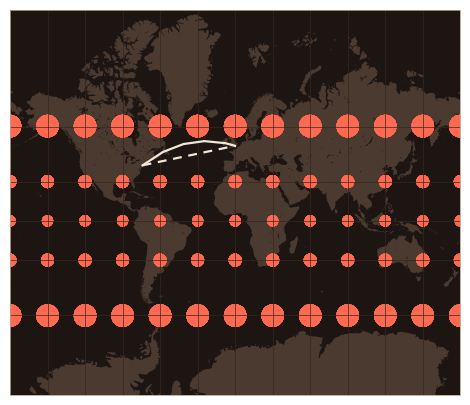

In [18]:
LAND50 = gpd.read_file(shpreader.natural_earth(resolution="50m", category="physical", name="land")).geometry.values
LAKES50 = gpd.read_file(shpreader.natural_earth(resolution="50m", category="physical", name="lakes")).geometry.values
print(f"for drawing regional maps: {len(LAND50)} land polygons, {len(LAKES50)} lakes (50m)")

STYLE = dict(ocean="#1D1512", land="#4A3A30", grid="#35271F", edge="#B4A28C", border="#6E5A4C",
             circle="#FF6A52", line="#F1E7D6")
NYC, LON_ = (-74.01, 40.71), (-0.13, 51.51)

def tissot_centers(p):
    if p["view"][0] == "extent" and "circle_km" not in p:
        w, e, s, n = p["view"][1]
        lons, lats = np.meshgrid(np.arange(w + 4, e, 8), np.arange(s + 4, n, 8))
        rad = 150
    else:
        lons, lats = np.meshgrid(np.arange(-150, 181, 30), np.arange(-60, 61, 30))
        rad = p.get("circle_km", 500)
    lons, lats = lons.ravel(), lats.ravel()
    keep = p.get("circle_domain", p["domain"])(lons, lats)
    return lons[keep], lats[keep], rad

def rhumb(a, b, n=200):
    y = lambda lat: np.log(np.tan(np.pi / 4 + np.radians(lat) / 2))
    t = np.linspace(0, 1, n)
    ys = y(a[1]) + t * (y(b[1]) - y(a[1]))
    return a[0] + t * (b[0] - a[0]), np.degrees(2 * np.arctan(np.exp(ys)) - np.pi / 2)

def draw(p, ax=None, circles=True, extras=True):
    own = ax is None
    if own:
        fig = plt.figure(figsize=(8, 5))
        ax = fig.add_subplot(1, 1, 1, projection=p["crs"])
    kind = p["view"][0]
    if kind == "global":
        ax.set_global()
    elif kind == "extent":
        ax.set_extent(p["view"][1], crs=ccrs.PlateCarree())
    elif kind == "proj":
        ax.set_extent(p["view"][1], crs=p["crs"])
    elif kind == "polar":
        ax.set_extent([-180, 180, p["view"][1], 90], crs=ccrs.PlateCarree())
        theta = np.linspace(0, 2 * np.pi, 200)
        ax.set_boundary(mpath.Path(np.c_[np.sin(theta), np.cos(theta)] * 0.5 + 0.5), transform=ax.transAxes)
    ax.set_facecolor(STYLE["ocean"])
    ax.spines["geo"].set_edgecolor(STYLE["edge"]); ax.spines["geo"].set_linewidth(0.6)
    if kind == "extent":
        # Regional maps: cut land and lakes down to the area shown before projecting. Shapes far
        # outside the view can turn inside-out. Lake Volta in Ghana, 87° from Transverse Mercator's
        # center line, became a polygon covering 95% of the map and hid all the land.
        w, e, s_, n = p["view"][1]
        box_ = (w - 10, max(s_ - 10, -90), e + 10, min(n + 10, 90))
        for layer, color in ((LAND50, STYLE["land"]), (LAKES50, STYLE["ocean"])):
            pieces = [g for g in shapely.clip_by_rect(layer, *box_) if not g.is_empty]
            ax.add_geometries(pieces, crs=ccrs.PlateCarree(), facecolor=color, edgecolor="none")
    else:
        ax.add_feature(cfeature.NaturalEarthFeature("physical", "land", "50m"), facecolor=STYLE["land"], edgecolor="none")
        ax.add_feature(cfeature.NaturalEarthFeature("physical", "lakes", "50m"), facecolor=STYLE["ocean"], edgecolor="none")
    if kind == "extent":   # regional maps get borders, and the US ones get states
        ax.add_feature(cfeature.NaturalEarthFeature("cultural", "admin_0_boundary_lines_land", "50m"),
                       facecolor="none", edgecolor=STYLE["border"], linewidth=0.6)
        if p["view"][1] == US:
            ax.add_feature(cfeature.NaturalEarthFeature("cultural", "admin_1_states_provinces_lakes", "50m"),
                           facecolor="none", edgecolor=STYLE["border"], linewidth=0.35)
    ax.gridlines(xlocs=range(-180, 181, 30), ylocs=range(-90, 91, 30), color=STYLE["grid"], linewidth=0.5)
    if circles:
        lons, lats, rad = tissot_centers(p)
        if len(lons):
            ax.tissot(rad_km=rad, lons=lons, lats=lats, n_samples=72, facecolor=STYLE["circle"], edgecolor="none", alpha=0.55)
    if extras and p.get("extra") in ("great_circle", "rhumb"):
        ax.plot([NYC[0], LON_[0]], [NYC[1], LON_[1]], transform=ccrs.Geodetic(), color=STYLE["line"], lw=1.6)
        if p["extra"] == "rhumb":
            x, y = rhumb(NYC, LON_)
            ax.plot(x, y, transform=ccrs.PlateCarree(), color=STYLE["line"], lw=1.6, ls=(0, (4, 3)))
    if extras and p.get("extra") == "utm_zone":
        for lon in (-90, -84):
            ax.plot([lon, lon], [0, 84], transform=ccrs.PlateCarree(), color=STYLE["line"], lw=1.2, ls=(0, (4, 3)))
    if own:
        return fig, ax

fig, ax = draw(next(p for p in P if p["slug"] == "mercator"))   # a first look
plt.show()

Look at that Mercator map before going on:
- The circles should grow toward the poles but stay round.
- The dashed rhumb line should be straight, and the solid shortest route should bow north.

If it looks right, the next cell draws and saves all 20.

In [19]:
for old in FIG.glob("[0-9][0-9]-*.png"):   # clear maps from earlier runs, in case numbering changed
    old.unlink()
saved = []
for p in P:
    fig, ax = draw(p)
    out = FIG / f"{p['n']:02d}-{p['slug']}.png"
    # transparent=True would also erase the ocean, so only the figure background goes clear
    fig.savefig(out, dpi=200, bbox_inches="tight", pad_inches=0.05, facecolor="none")
    plt.close(fig)
    saved.append(out)
    print(f"{out.name:40s} {out.stat().st_size / 1024:6.0f} KB")
print(f"\n{len(saved)} maps saved to {FIG}")

01-gnomonic.png                             190 KB
02-stereographic.png                        163 KB
03-orthographic.png                         185 KB
04-equirectangular.png                      130 KB
05-azimuthal-equidistant.png                201 KB
06-mercator.png                             146 KB
07-sinusoidal.png                           208 KB
08-bonne.png                                237 KB
09-lambert-conformal-conic.png              174 KB
10-lambert-azimuthal-equal-area.png         196 KB
11-transverse-mercator.png                  148 KB
12-albers.png                               174 KB
13-mollweide.png                            206 KB
14-polyconic.png                            148 KB
15-gall-peters.png                          153 KB
16-van-der-grinten.png                      202 KB
17-winkel-tripel.png                        218 KB
18-goode-homolosine.png                     191 KB
19-robinson.png                             204 KB
20-equal-earth.png             

## 6 · Contact sheet

All 20 on one image, in date order, for the top of the post and the portfolio card. No circles here; at this size they'd just be noise.

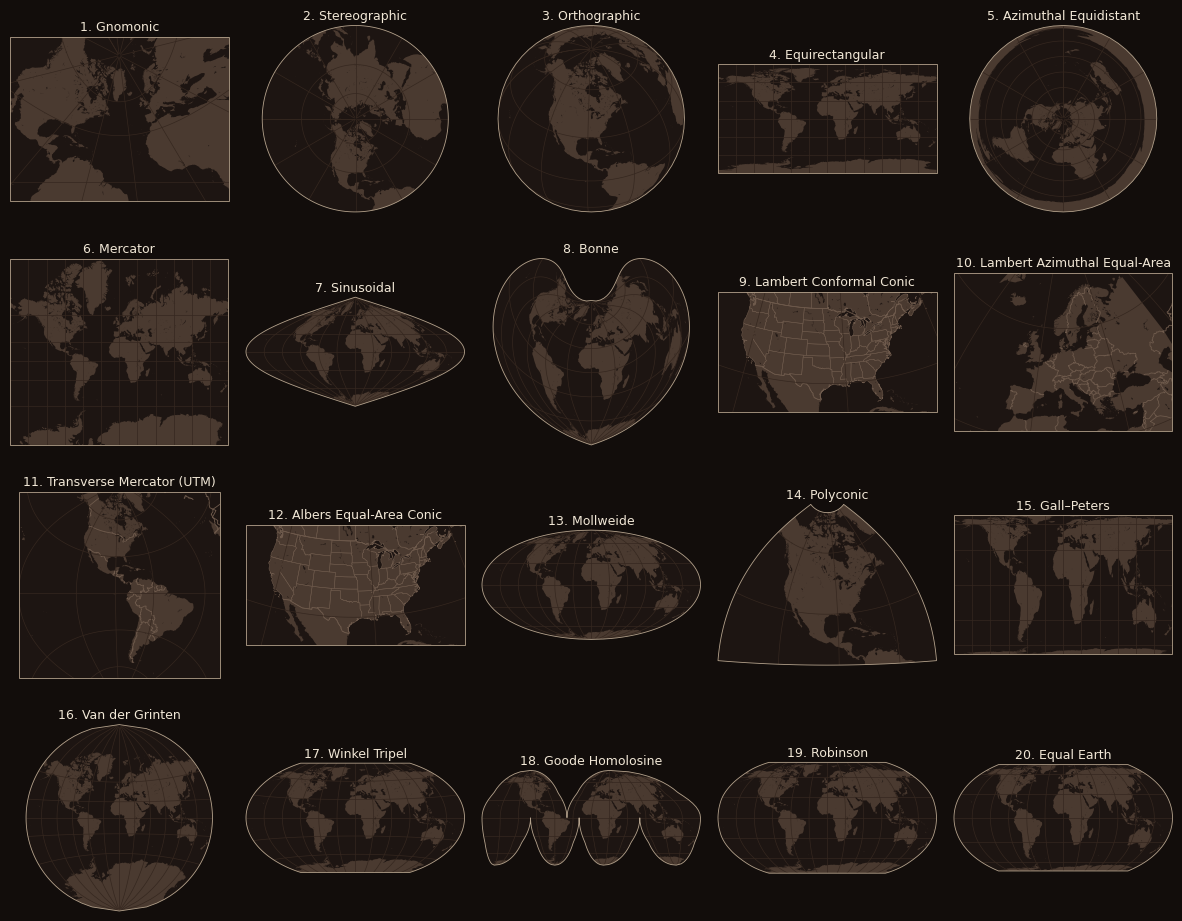

saved /Users/devi/map-projections/figures/00-contact-sheet.png 816 KB


In [20]:
fig = plt.figure(figsize=(15, 11.5))
fig.patch.set_facecolor("#120D0B")
for p in P:
    ax = fig.add_subplot(4, 5, p["n"], projection=p["crs"])
    draw(p, ax=ax, circles=False, extras=False)
    ax.set_title(f"{p['n']}. {p['name']}", color=STYLE["line"], fontsize=9, pad=4)
fig.subplots_adjust(wspace=0.08, hspace=0.25)
out = FIG / "00-contact-sheet.png"
fig.savefig(out, dpi=150, bbox_inches="tight", facecolor=fig.get_facecolor())
plt.show()
print("saved", out, f"{out.stat().st_size / 1024:.0f} KB")

## 7 · How many projections are there, anyway?

There's no official count. Snyder's USGS *Album of Map Projections* (1989) says there are "hundreds of known projection systems" and that the number of ways to handle distortion "is infinite." So instead of quoting a number, we count two real things:

1. **Projection methods in PROJ**, the open-source library underneath QGIS, GDAL, PostGIS and pyproj. PROJ also lists non-projection tools like datum shifts, so we subtract the operations its docs file under "conversions" and "transformations."
2. **Ready-made projected coordinate systems in the EPSG registry.** These are projections with specific settings attached, like "NAD83 / Illinois East (ftUS)." This is what you pick from in GIS software.

**Choice:** the non-projection list comes from proj.org's conversions and transformations pages, plus a few aliases. If a future PROJ adds a new datum-shift tool, it would get counted as a projection until it's added here.

In [21]:
from pyproj.database import query_crs_info
from pyproj.enums import PJType

NOT_PROJECTIONS = {
    # proj.org "Conversions"
    "axisswap", "cart", "geoc", "latlon", "noop", "pop", "push", "set", "topocentric", "unitconvert",
    # proj.org "Transformations"
    "affine", "defmodel", "deformation", "geogoffset", "gridshift", "helmert", "horner", "molodensky",
    "molobadekas", "hgridshift", "tinshift", "vertoffset", "vgridshift", "xyzgridshift",
    # plumbing and aliases
    "pipeline", "geocent", "latlong", "lonlat", "longlat",
}
ops = pyproj.list.get_proj_operations_map()
projections = sorted(k for k in ops if k not in NOT_PROJECTIONS)
print(f"PROJ {pyproj.proj_version_str}: {len(ops)} operations, of which {len(projections)} are projections")

ours = {p["crs"].to_dict().get("proj") for p in P}
print("our 20 use these PROJ methods:", sorted(ours))
print("all of them found in PROJ:", ours <= set(ops))

epsg_projected = query_crs_info(auth_name="EPSG", pj_types=PJType.PROJECTED_CRS, allow_deprecated=False)
epsg_geographic = query_crs_info(auth_name="EPSG", pj_types=[PJType.GEOGRAPHIC_2D_CRS], allow_deprecated=False)
print(f"EPSG registry: {len(epsg_projected):,} projected coordinate systems, {len(epsg_geographic):,} geographic (lat/long) ones")

chicago = [c for c in epsg_projected if c.area_of_use and c.area_of_use.west <= -87.63 <= c.area_of_use.east
           and c.area_of_use.south <= 41.88 <= c.area_of_use.north]
print(f"...of which {len(chicago):,} are valid for downtown Chicago")

PROJ 9.5.1: 184 operations, of which 155 are projections
our 20 use these PROJ methods: ['aea', 'aeqd', 'bonne', 'cea', 'eqc', 'eqearth', 'gnom', 'igh', 'laea', 'lcc', 'merc', 'moll', 'ortho', 'poly', 'robin', 'sinu', 'stere', 'tmerc', 'vandg', 'wintri']
all of them found in PROJ: True
EPSG registry: 5,291 projected coordinate systems, 585 geographic (lat/long) ones
...of which 50 are valid for downtown Chicago


/Users/devi/miniconda3/envs/geo/lib/python3.12/site-packages/pyproj/crs/crs.py:1295: UserWarning: You will likely lose important projection information when converting to a PROJ string from another format. See: https://proj.org/faq.html#what-is-the-best-format-for-describing-coordinate-reference-systems
  proj = self._crs.to_proj4(version=version)


**Check:** the WGS 84 line below should say *geographic*, not projected. WGS 84 is a datum (a model of the Earth's shape plus the lat/long grid on it), not a projection. Web Mercator's official EPSG name is "Pseudo-Mercator," and Illinois State Plane uses Transverse Mercator.

In [22]:
for code in ["EPSG:4326", "EPSG:4269", "EPSG:3857", "EPSG:32616", "EPSG:3435", "EPSG:5070", "EPSG:3035", "EPSG:8857"]:
    c = pyproj.CRS(code)
    method = c.coordinate_operation.method_name if c.is_projected else "(none: plain latitude/longitude)"
    print(f"{code:11s} {'projected ' if c.is_projected else 'geographic'}  {c.name:38s} {method}")

EPSG:4326   geographic  WGS 84                                 (none: plain latitude/longitude)
EPSG:4269   geographic  NAD83                                  (none: plain latitude/longitude)
EPSG:3857   projected   WGS 84 / Pseudo-Mercator               Popular Visualisation Pseudo Mercator
EPSG:32616  projected   WGS 84 / UTM zone 16N                  Transverse Mercator
EPSG:3435   projected   NAD83 / Illinois East (ftUS)           Transverse Mercator
EPSG:5070   projected   NAD83 / Conus Albers                   Albers Equal Area
EPSG:3035   projected   ETRS89-extended / LAEA Europe          Lambert Azimuthal Equal Area
EPSG:8857   projected   WGS 84 / Equal Earth Greenwich         Equal Earth


## 8 · Data for the interactive slider

The page has a slider that morphs the world from Mercator into Equal Earth. It needs three outlines: Greenland, Africa, and everything else. It also needs the true areas, so the page can compare what you see with reality.

- **Data:** Natural Earth countries at 110m, the coarsest version, since the browser redraws it on every slider move. Coordinates are rounded to 0.01° (about 1 km), which is plenty at this size.
- **Winding order:** D3, the JavaScript mapping library, wants each outline's points to run **clockwise**, which is the opposite of the GeoJSON standard. Get it backwards and D3 fills "the whole world except this country." So every polygon gets reoriented here.

In [23]:
import json
from shapely.geometry.polygon import orient

countries110 = gpd.read_file(shpreader.natural_earth(resolution="110m", category="cultural", name="admin_0_countries"))
is_gl = countries110["ADMIN"] == "Greenland"
is_af = countries110["CONTINENT"] == "Africa"
parts = {
    "other": countries110.loc[~is_gl & ~is_af].geometry.union_all(),
    "greenland": countries110.loc[is_gl].geometry.union_all(),
    "africa": countries110.loc[is_af].geometry.union_all(),
}

def for_d3(geom):
    geom = shapely.transform(geom, lambda xy: np.round(xy, 2))
    polys = getattr(geom, "geoms", [geom])
    return sgeom.MultiPolygon([orient(p, sign=-1.0) for p in polys if p.geom_type == "Polygon" and not p.is_empty])

features = []
for name, geom in parts.items():
    props = {"name": name}
    if name in ("greenland", "africa"):
        props["true_km2"] = round(true_km2[name.capitalize()])   # measured on the ellipsoid in section 1
    features.append({"type": "Feature", "properties": props, "geometry": sgeom.mapping(for_d3(geom))})

out = DATA / "interactive_world.json"
out.write_text(json.dumps({"type": "FeatureCollection", "features": features}, separators=(",", ":")))
print(f"wrote {out.name}: {out.stat().st_size / 1024:.0f} KB")
for f in features:
    n_polys = len(f["geometry"]["coordinates"])
    print(f"  {f['properties']['name']:10s} {n_polys:4d} polygons  {f['properties'].get('true_km2', ''):>12}")

wrote interactive_world.json: 76 KB
  other       125 polygons              
  greenland     1 polygons       2171354
  africa        2 polygons      29890202
